# 04. Centros de distribuição: rerandomização com poucas unidades

**A decisão:** a operação testou um novo motor de roteirização e quer saber se ele
melhora a **taxa de entrega no prazo**. A pergunta parece trivial, mas o desenho
não é: as unidades experimentais são apenas **24 centros de distribuição (CDs)**, e
eles são muito diferentes entre si em volume (`throughput_pre`) e em número de docas
(`dock_count`). Com tão poucas unidades, um único sorteio pode sair desbalanceado por
puro azar, concentrando os CDs grandes em um dos braços.

**O ajuste:** rerandomizar até o sorteio ficar equilibrado (critério de Mahalanobis)
e, em seguida, usar uma inferência que **honre esse mesmo critério**. Balancear sem
ajustar a inferência invalida o teste; ajustar a inferência sem balancear desperdiça
precisão. Os dois andam juntos.

Teoria de apoio: [II. Desenhos](../../../docs/pt-br/teoria/02-desenhos.md) (tópico 6)
e [IV. Inferência](../../../docs/pt-br/teoria/04-inferencia.md) (tópico 13).


## O reflexo natural (e por que ele não basta)

O instinto é o de sempre: separar os 24 CDs em tratamento e controle e rodar um
`ttest_ind` na taxa de entrega no prazo. Aqui aparecem **dois** problemas distintos,
e é importante não confundi-los.

- **(a) Desbalanceamento.** Com apenas 24 unidades, um único sorteio facilmente sai
  desbalanceado em `throughput_pre` ou `dock_count`. E, ao contrário de um estudo com
  milhares de usuários, esse desequilíbrio **enviesa uma leitura única**: se os CDs de
  alto volume caírem quase todos no tratamento, você mede o efeito do motor de
  roteirização confundido com o efeito de ser um CD grande.
- **(b) n pequeno.** Com n=24, intervalos por aproximação normal ficam frágeis e,
  mais importante, o **poder** do teste é baixo.

A rerandomização resolve **(a)**: ela recusa sorteios ruins antes de você olhar o
resultado. O teste de randomização mantém a inferência válida para **(b)**, sem depender
da normalidade. Mas nada disso cria poder: só mais unidades (ou um desenho intra-CD)
resolve o poder baixo, e é com isso que fechamos o capítulo.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd


def _find_data():
    """Locate examples/use_cases/data whether run from the notebook or the root."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        for cand in (base / "data", base / "examples" / "use_cases" / "data"):
            if (cand / "ecommerce_checkout.csv").exists():
                return cand
    raise FileNotFoundError("Could not locate examples/use_cases/data")


DATA = _find_data()

df = pd.read_csv(DATA / "logistics_dc.csv")
print(df.shape, "distribution centers")
df.head()

(24, 6) distribution centers


,dc_id,region,throughput_pre,dock_count,on_time_y0,on_time_y1
0,1,Nordeste,55945,19,89.256,90.756
1,2,Centro-Oeste,40759,12,82.388,83.888
2,3,Sul,56853,11,88.811,90.311
3,4,Sul,63394,23,92.059,93.559
4,5,Centro-Oeste,54492,12,87.349,88.849


## Um CRD comum pode sair desbalanceado

Comecemos honestos: primeiro um sorteio de CRD comum e o balanço das covariáveis. Com
24 unidades, não é nada raro que a **diferença média padronizada** (SMD) de
`throughput_pre` ou `dock_count` ultrapasse 0,1, o limiar usual para dizer que um braço
não está comparável ao outro. Rode a célula e olhe os números: é exatamente o tipo de
sorteio que preferiríamos nunca ter aceitado.


In [2]:
from skxperiments.design.crd import CRD
from skxperiments.design.balance import check_balance

crd = CRD(p=0.5, seed=404).randomize(df[["region", "throughput_pre", "dock_count"]].copy())
check_balance(crd)[["covariate", "smd"]].round(3)

,covariate,smd
0,throughput_pre,-0.269
1,dock_count,-0.145


## Rerandomizar até equilibrar

`ReRandomizedCRD` só aceita sorteios cuja **distância de Mahalanobis** entre os braços
fique abaixo de um limiar. Mahalanobis é a generalização multivariada da distância
padronizada: mede o desequilíbrio conjunto em `throughput_pre` e `dock_count` de uma vez,
já levando em conta a correlação entre elas.

Escolhemos o limiar com `chi2.ppf(0.10, df=2)`, ou seja, aceitamos apenas os ~10% de
sorteios mais equilibrados (2 graus de liberdade para 2 covariáveis). Com n pequeno, um
limiar **não estrito demais** é proposital: apertar demais faz o sorteador rejeitar quase
tudo e demorar a convergir. Depois da rerandomização, o balanço deve melhorar de forma
visível.


In [3]:
from scipy.stats import chi2

from skxperiments.design.rerandomized_crd import ReRandomizedCRD
from skxperiments.diagnostics import BalanceReport

threshold = float(chi2.ppf(0.10, df=2))
design = ReRandomizedCRD(
    covariates=["throughput_pre", "dock_count"], threshold=threshold,
    p=0.5, seed=404, max_attempts=20000,
)
assignment = design.randomize(df[["region", "throughput_pre", "dock_count"]].copy())
report = BalanceReport().run(assignment)
print("imbalanced covariates:", report.imbalanced)

imbalanced covariates: []


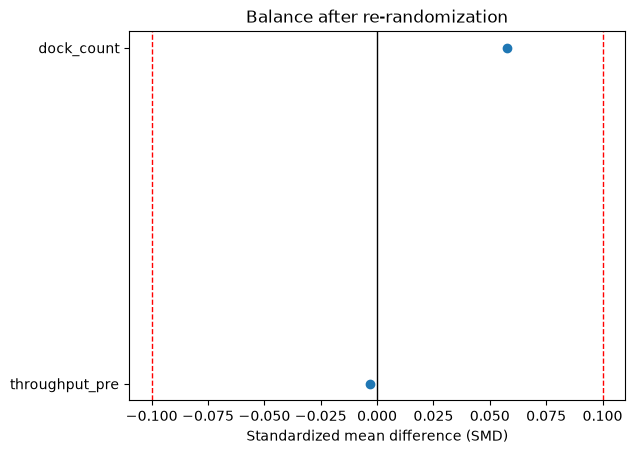

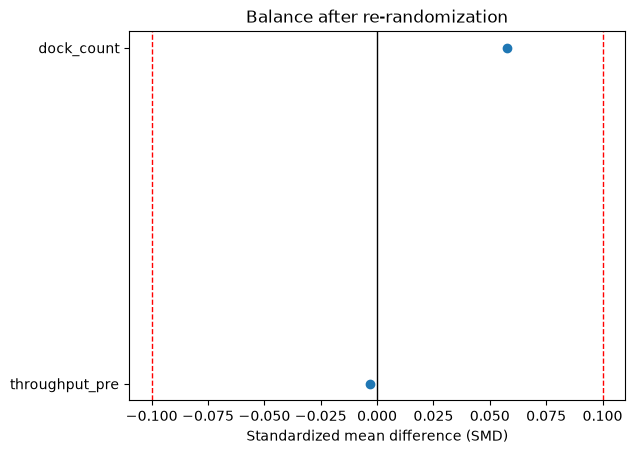

In [4]:
from skxperiments.reporting import plot_balance

ax = plot_balance(report)
ax.set_title("Balance after re-randomization")
ax.figure

## Inferência que respeita o critério

Agora anexamos o desfecho (a taxa de entrega no prazo) e analisamos. Aqui está a sutileza
que separa um teste válido de um teste conservador: se você rerandomizou o **desenho** mas
depois faz uma permutação ingênua (qualquer divisão 12x12), o teste passa a considerar
sorteios que o próprio desenho teria recusado, e fica conservador.

`RandomizationTest` evita isso rerandomizando **pelo mesmo mecanismo** do desenho (via
`draw()`): as permutações da hipótese nula também obedecem ao critério de rerandomização.
A distribuição nula passa a refletir exatamente o processo que gerou a atribuição, e o
teste continua válido. Como C(24,12) é gigantesco, o p-valor sai por Monte Carlo. Comparamos
com o intervalo de Neyman, que aqui serve de contraponto por aproximação normal.


In [5]:
from skxperiments.core.assignment import CRDAssignment
from skxperiments.estimators.difference_in_means import DifferenceInMeans
from skxperiments.inference import RandomizationTest, NeymanCI

t = assignment.data_[assignment.treatment_col_].to_numpy()
data = assignment.data_.copy()
data["on_time"] = np.where(t == 1, df["on_time_y1"].to_numpy(), df["on_time_y0"].to_numpy())
assignment = CRDAssignment(
    data=data, treatment_col=assignment.treatment_col_, design=design, seed=404
)

rand = RandomizationTest(
    estimator=DifferenceInMeans(outcome_col="on_time"), n_permutations=2000, seed=0
).fit(assignment).estimate()
neyman = NeymanCI(estimator=DifferenceInMeans(outcome_col="on_time")).fit(assignment).estimate()

print(f"Randomization test: ATE={rand.ate:.3f} pp, p={rand.p_value:.4f}")
print(f"Neyman CI:          ATE={neyman.ate:.3f} pp, "
      f"CI=({neyman.ci[0]:.3f}, {neyman.ci[1]:.3f})")

Randomization test: ATE=1.842 pp, p=0.0125
Neyman CI:          ATE=1.842 pp, CI=(0.152, 3.531)


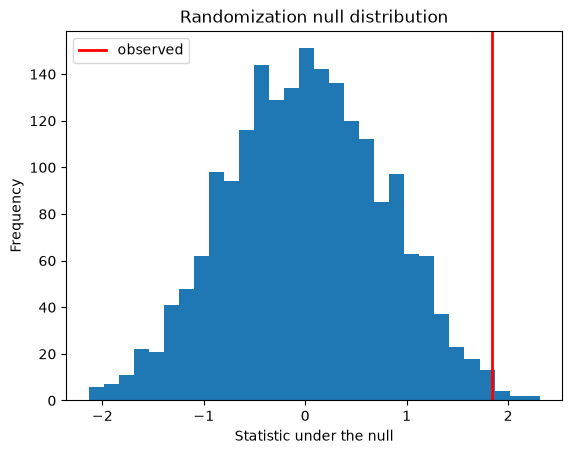

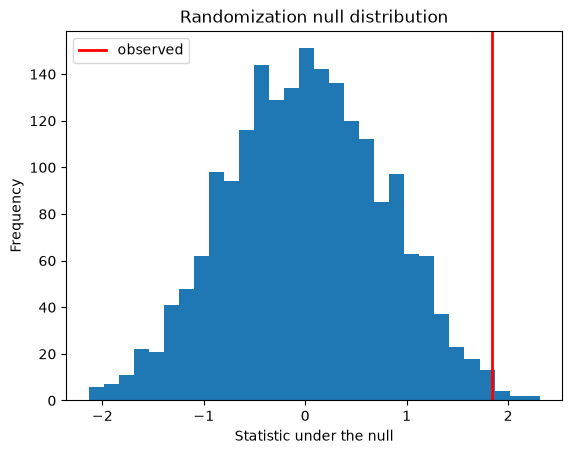

In [6]:
from skxperiments.reporting import plot_null_distribution

ax = plot_null_distribution(rand)
ax.set_title("Randomization null distribution")
ax.figure

## Quebrando o teste: poder com poucas unidades

Feito tudo certo, ainda resta o fato incômodo: 24 unidades é um experimento pequeno. Em
vez de perguntar "deu significativo?", vamos fazer a pergunta de poder ao contrário, que é
a pergunta honesta:

1. qual o **menor efeito** que estes 24 CDs conseguiriam detectar de forma confiável?
2. quanto de **poder** de fato tínhamos para o efeito real de +1,5 pp?

Essas duas perguntas dizem se um resultado (significativo ou não) merece confiança, antes
mesmo de olharmos o p-valor.


In [7]:
# Few units means low power. With only 24 DCs, what is the smallest effect we could
# reliably detect, and how much power did we actually have for the true +1.5pp?
from skxperiments.design.power import power_analysis

sd = float(df["on_time_y0"].std())
mde_24 = power_analysis(n=24, power=0.8, std=sd, alpha=0.05).mde
power_15 = power_analysis(n=24, mde=1.5, std=sd, alpha=0.05).power
print(f"on-time std: {sd:.2f} pp")
print(f"smallest effect detectable at n=24 with 80% power: {mde_24:.2f} pp")
print(f"actual power for the true +1.5 pp effect at n=24: {power_15:.1%}")

on-time std: 2.07 pp
smallest effect detectable at n=24 with 80% power: 2.37 pp
actual power for the true +1.5 pp effect at n=24: 42.6%


## O limite honesto

Leia os números com calma: em n=24, o menor efeito detectável de forma confiável a 80% de
poder é de cerca de **2,37 pp**, mas o efeito verdadeiro de **+1,5 pp** tinha apenas cerca
de **43% de poder**, pior que cara ou coroa. Isso muda como você lê o resultado. Um
resultado **não** significativo aqui seria genuinamente ambíguo: ausência de evidência, não
evidência de ausência. E mesmo a leitura significativa que obtivemos é um pouco de sorte.

Dois limites honestos, que nenhuma rerandomização remove:

1. **Poder baixo com poucas unidades.** Rerandomizar equilibra os braços, mas não fabrica
   poder. Para poder de verdade você precisa de mais unidades ou de um desenho **intra-CD /
   crossover** (cada CD como seu próprio controle ao longo do tempo).
2. **Independência entre CDs.** Rotas e regiões se sobrepõem. Se tratar um CD desloca volume
   para outro, o `SUTVA` quebra e você quer um desenho de **cluster / geo**, fora do escopo
   da v1.

Prático: com poucas unidades, **pré-registre** a análise e leia um resultado nulo como
"subpoderado", não como "sem efeito".


## Decisão, limites e próximo passo

**A decisão.** O efeito (cerca de +1,5 pp) foi recuperado, a rerandomização equilibrou os
braços e o teste de randomização rejeita a nula. Mas sustente essa conclusão com humildade:
com ~43% de poder, trate-a como **encorajadora, não fechada**. O passo responsável é rodar
um teste confirmatório maior ou mais longo antes de um rollout completo.

**Limites deste capítulo.**
1. Poder baixo é **estrutural** com poucas unidades, não um detalhe de configuração.
2. `SUTVA` pode falhar se os CDs interferem entre si.
3. O `power_analysis` embutido é uma **aproximação de duas amostras com desfecho contínuo`;
   para uma taxa binária ele serve de guia, não de resposta exata.

**Próximo passo:** [05. Muitas métricas no streaming](05_streaming_many_metrics.ipynb),
onde o inimigo deixa de ser o número de unidades e passa a ser o número de **métricas**.
